1: imports, paths, splits

In [1]:
import numpy as np, pandas as pd, json, time
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

ROOT = Path(r"D:\Pancreatic_GraphTCDR")
D = ROOT/"data"; RAW = D/"raw"; P = D/"processed"; T = P/"target_v2"
RES = ROOT/"results"/"v2"

train = pd.read_csv(T/"train_v2.csv"); val = pd.read_csv(T/"val_v2.csv"); test = pd.read_csv(T/"test_v2.csv")
assert len(train)==12929 and len(val)==1306 and len(test)==3802
pol = json.load(open(T/"target_policy.json")); LO, HI = pol["LO"], pol["HI"]
panc_idx = set(train["omics_index"]) | set(val["omics_index"]) | set(test["omics_index"])

Z402 = np.load(P/"ae_embeddings_402x512.npy").astype(np.float32)   # saved earlier, verified vs the 28-line CSV (max diff 5e-6)
fp = np.load(P/"drug_morgan_fingerprints_1228x2048.npy").astype(np.float32)
print("Z402", Z402.shape, "| fp", fp.shape, "| pancreatic lines", len(panc_idx), "| LO/HI", round(LO,4), round(HI,4))

Z402 (402, 512) | fp (1228, 2048) | pancreatic lines 28 | LO/HI -3.2443 1.2946


 build the pair table

In [2]:
names = pd.read_csv(RAW/"cellLineName402.csv")
smiles = pd.read_csv(P/"drug_smiles_1228.csv")

resp = pd.read_csv(RAW/"secondary-screen-dose-response-curve-parameters.csv",
                   usecols=["ccle_name", "name", "ic50", "r2"])
resp["ic50"] = pd.to_numeric(resp["ic50"], errors="coerce")
resp = resp[np.isfinite(resp["ic50"]) & (resp["ic50"] > 0)].copy()
resp["log_ic50"] = np.log10(resp["ic50"])

resp["omics_index"] = resp["ccle_name"].map(dict(zip(names["cellLineName"], names["index"])))
resp["drug_index"] = resp["name"].map(dict(zip(smiles["name"], range(len(smiles)))))
resp = resp.dropna(subset=["omics_index", "drug_index"])
resp[["omics_index", "drug_index"]] = resp[["omics_index", "drug_index"]].astype(int)

allp = (resp.groupby(["omics_index", "drug_index"], as_index=False)
            .agg(log_ic50=("log_ic50", "median"), r2=("r2", "median")))

pp = allp[allp.omics_index.isin(panc_idx)]
mine = pd.concat([train, val, test])[["omics_index", "drug_index", "log_ic50"]]
m = mine.merge(pp, on=["omics_index", "drug_index"], suffixes=("_old", "_new"))
print("all pairs:", len(allp), "| pancreatic rebuilt:", len(pp), "(expect 18037)",
      "| max diff:", (m.log_ic50_old - m.log_ic50_new).abs().max())
assert len(pp) == 18037

all pairs: 278090 | pancreatic rebuilt: 18037 (expect 18037) | max diff: 5.684341886080802e-14


leakage-controlled pool and checks

In [3]:
heldout = set(val["drug_index"]) | set(test["drug_index"])
pool = allp[~allp.drug_index.isin(heldout)].copy()
assert set(pool.drug_index).isdisjoint(heldout)
pool["y_clip"] = pool["log_ic50"].clip(LO, HI)          # same fixed bounds, not recomputed
panc_pool = pool[pool.omics_index.isin(panc_idx)]

print("pan-cancer pool:", len(pool), "pairs |", pool.drug_index.nunique(), "drugs |", pool.omics_index.nunique(), "lines")
print("pancreatic-only pool:", len(panc_pool), "(must equal 12929)")
assert len(panc_pool) == 12929

pan-cancer pool: 199623 pairs | 883 drugs | 402 lines
pancreatic-only pool: 12929 (must equal 12929)


 RF run (timing check first)

In [6]:
def feats(df, mu=None, sd=None):
    C = Z402[df.omics_index.values]
    if mu is None: mu, sd = C.mean(0), C.std(0) + 1e-6
    return np.hstack([(C - mu)/sd, fp[df.drug_index.values]]).astype(np.float32), mu, sd

yte = test["y_clip"].values

def run(name, df, seeds=(42, 43, 44), n_est=300):
    X, mu, sd = feats(df); Xt = feats(test, mu, sd)[0]
    scores = []
    for s in seeds:
        t0 = time.time()
        rf = RandomForestRegressor(n_est, max_features="sqrt", min_samples_leaf=3,
                                   random_state=s, n_jobs=-1).fit(X, df["y_clip"].values)
        p = rf.predict(Xt)
        pd.DataFrame({"pred_clip": p}).to_csv(RES/f"pred_rf_ae_{name}_s{s}.csv", index=False)
        scores.append(r2_score(yte, p))
        print(f"{name} s{s}: R2 {scores[-1]:.4f} MAE {mean_absolute_error(yte,p):.4f} "
              f"rho {spearmanr(yte,p)[0]:.4f} ({time.time()-t0:.0f}s)")
    print(name, "mean R2 %.4f" % np.mean(scores))

run("pancancer", pool)

pancancer s42: R2 0.1730 MAE 0.5207 rho 0.4423 (280s)
pancancer s43: R2 0.1526 MAE 0.5250 rho 0.4267 (271s)
pancancer s44: R2 0.1765 MAE 0.5204 rho 0.4447 (266s)
pancancer mean R2 0.1674


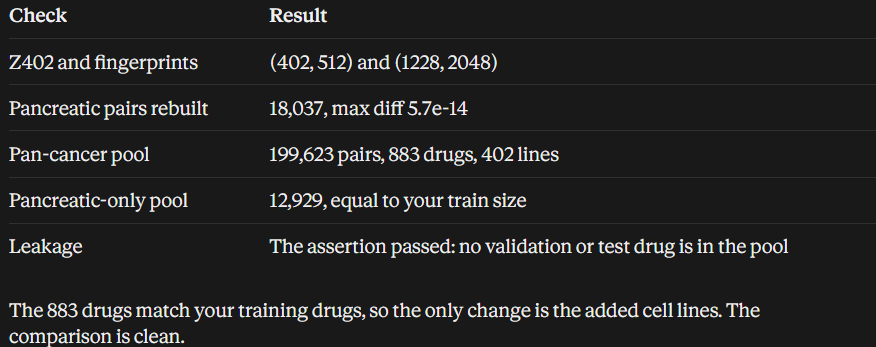

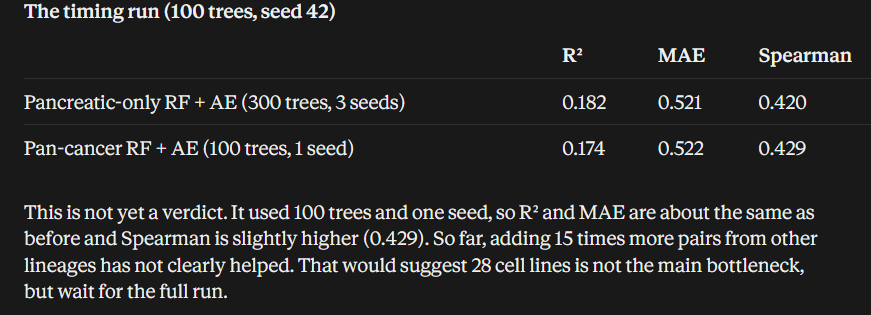

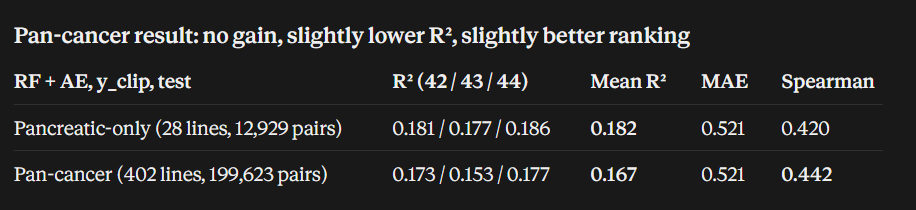